In [889]:
# 길이, 높이, 넓이로 무게를 추정 : 다중회귀(특성값이 여러 개인 것을 가지고 모델학습)

# 특성값을 더 추가
# - PolynomialFeatures
# - 정확도를 더 높이기 위해
# - degree추가

# 과대적합 : 훈련데이터 정확성은 높은데, 테스트데이터는 현저히 정확도가 떨어짐

# 규제 : 과대적합 문제 해결을 위해 하는 것으로 정규화작업을 해야 규제가 가능
#  - Ridge규제
#  - 옵션 : alpha 강도조절로 과대적합 문제 해결

import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.preprocessing import PolynomialFeatures # 다항특성 자동생성
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스
from sklearn.model_selection import train_test_split

In [890]:
df = pd.read_csv('data/perch_full.csv')
df.head()

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00
2,15.0,3.82,2.43
3,16.2,4.59,2.63
4,17.4,4.59,2.94


In [891]:
df.shape

(56, 3)

In [892]:
# 무게데이터
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [893]:
len(perch_weight)

56

In [894]:
# 훈련데이터, 테스트데이터 분리
train_data, test_data, train_label, test_label = \
train_test_split(df,perch_weight, random_state=42) # random_state로 훈련데이터 고정하면, 결과가 고정. 학습 시에는 제거해야 함

In [895]:
# 특성값을 추가
# length, height, width
# length**2, height**2, width**2
from sklearn.preprocessing import PolynomialFeatures


In [896]:
# 다항특성추가 - polynomialFeatures
poly = PolynomialFeatures(degree=17,include_bias=False) # 다항의 특성을 제곱으로 늘렸다는 의미, 즉, 2차항까지 늘렸다는 의미 -> 설명력을 높이기 위해(보통, 2~3항까지)
# 결과는 세 독립변수 1차항, 2차항, 독립변수간의 곱의 형태로 9개가 발생하게 됨. 과도한 차수를 하면, 과적합 문제 -> 규제가 필요(정규화). include_bias는 절편을 의미함
poly.fit([[2,3]])
train_poly = poly.transform([[2,3]])
train_poly

array([[2.00000000e+00, 3.00000000e+00, 4.00000000e+00, 6.00000000e+00,
        9.00000000e+00, 8.00000000e+00, 1.20000000e+01, 1.80000000e+01,
        2.70000000e+01, 1.60000000e+01, 2.40000000e+01, 3.60000000e+01,
        5.40000000e+01, 8.10000000e+01, 3.20000000e+01, 4.80000000e+01,
        7.20000000e+01, 1.08000000e+02, 1.62000000e+02, 2.43000000e+02,
        6.40000000e+01, 9.60000000e+01, 1.44000000e+02, 2.16000000e+02,
        3.24000000e+02, 4.86000000e+02, 7.29000000e+02, 1.28000000e+02,
        1.92000000e+02, 2.88000000e+02, 4.32000000e+02, 6.48000000e+02,
        9.72000000e+02, 1.45800000e+03, 2.18700000e+03, 2.56000000e+02,
        3.84000000e+02, 5.76000000e+02, 8.64000000e+02, 1.29600000e+03,
        1.94400000e+03, 2.91600000e+03, 4.37400000e+03, 6.56100000e+03,
        5.12000000e+02, 7.68000000e+02, 1.15200000e+03, 1.72800000e+03,
        2.59200000e+03, 3.88800000e+03, 5.83200000e+03, 8.74800000e+03,
        1.31220000e+04, 1.96830000e+04, 1.02400000e+03, 1.536000

In [897]:
poly.fit(train_data)
train_poly = poly.transform(train_data)
# print(train_data.shape) # 여기는 자료가 3개
test_poly = poly.transform(test_data)
print(train_poly.shape) # 여기는 자료 9개 -> 정확도 증가

(42, 1139)


In [898]:
train_poly[:2]

array([[1.96000000e+01, 5.14000000e+00, 3.04000000e+00, ...,
        4.62412954e+08, 2.73489374e+08, 1.61752470e+08],
       [2.20000000e+01, 5.88000000e+00, 3.52000000e+00, ...,
        5.45625431e+09, 3.26632911e+09, 1.95535348e+09]], shape=(2, 1139))

In [899]:
# 규제, 정규화작업 진행 - 테스트데이터 정확도를 높일 수 있음
# StandardScaler() - 정규화도 있고, 규제 기능도 있음
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [ ]:
alpha_list = [0.001,0.01,0.1,1,10,100]
# 규제에는 릿지, 라쏘 2가지가 있음 : 과적합(train점수는 높고(거의 완벽), test점수는 낮음(60~70대)), 다중공선성 시 사용

train_score = []
test_score = []
for alpha in alpha_list:
    
    ridge = Ridge(alpha=alpha) # 릿지에는 알파값이 있음. 돌려보고 난 후 값을 변경시키면서 결정
    ridge.fit(train_scaled,train_label)

# 정확도
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)
print('완료')

완료


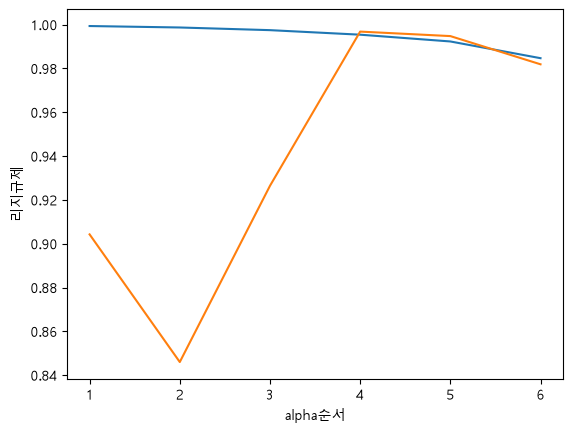

In [901]:
# 선그래프
no_list=[1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha순서')
plt.ylabel('리지규제')
plt.show()

In [887]:
print('train정확도:',score)
print('test정확도:',score2)

train정확도: 0.9954095289500754
test정확도: 0.9968190875658797


In [879]:
print(poly.get_feature_names_out()) # 다항에 있는 식의 형태를 알 수 있음

['length' ' height' ' width' ... ' height^2  width^15' ' height  width^16'
 ' width^17']


In [880]:
# degree=2로 했을 때의 예측결과
# 데이터 학습
lr = LinearRegression()
lr.fit(train_poly, train_label)
# 데이터 예측
predict = lr.predict(test_poly)
print('예측:',predict)
# 정확도
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print('train정확도:',score)
print('test정확도:',score2)


예측: [ 162.77113101  162.79491673  160.14689041  163.01538667  162.50522395
  629.86743389  128.12669465  163.20251711  838.8168149   162.82974185
 -754.35372289  162.77298931  161.68679393  178.02117583]
train정확도: 0.9378712937807022
test정확도: -1.2988231241629196


In [881]:
## 원본으로 예측했을 때와 위의 예측결과 비교
# 데이터 학습
lr = LinearRegression()
lr.fit(train_data, train_label)
# 데이터 예측
predict = lr.predict(test_data)
print('예측:',predict)
# 정확도
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print('train정확도:',score)
print('test정확도:',score2)

# 예측결과, 무게에 -가 있어서 좋지 않음

예측: [-322.78309496   52.96101903  329.77783424  171.46884473  149.65836217
  789.639144    383.68482432  250.05247716  813.2470793   126.13660027
  980.20626415  -33.35965799  357.76466578  421.8675313 ]
train정확도: 0.9559326821885706
test정확도: 0.8796419177546366
